# Ejercicio 2 · Transfer learning con pocos datos
### Hojas de café sanas vs. enfermas con 10 fotos por clase

**Deep Learning · Semana 2 · 2026-2**

**La pregunta del día:** en la semana 1 vimos que el deep learning necesita **muchos datos**: con pocos, el ML clásico le ganaba a la red. Y en el ejercicio 1 entrenamos LeNet-5 con 55 000 imágenes. ¿Qué hace uno si solo tiene **10 imágenes por clase**?

La respuesta de la industria se llama ***transfer learning*** (aprendizaje por transferencia): no empezar de cero, sino tomar una red que **ya aprendió a ver** con millones de fotos y enseñarle solo lo nuevo.

### El problema: detectar la roya en una hoja de café
La **roya del café** es un hongo (*Hemileia vastatrix*) que deja manchas amarillas y anaranjadas en el envés de la hoja; la hoja se cae y la planta produce menos. En Colombia, la epidemia de roya de 2008 a 2011 bajó fuertemente la cosecha y obligó a renovar miles de hectáreas con variedades resistentes como la **Castillo**, de Cenicafé. Detectarla a tiempo, hoja por hoja, es trabajo de un agrónomo que camina el cafetal.

¿Puede una red hacerlo con una foto de celular? El problema es que **nadie tiene 10 000 fotos etiquetadas de hojas de café**: etiquetar exige que un experto mire cada hoja.

### Plan de la clase
| # | Parte | Pregunta |
|---|---|---|
| 1 | Los datos | ¿Qué fotos tenemos y cómo se preparan para una red preentrenada? |
| 2 | Los competidores | Desde cero, congelada o con ajuste fino: ¿cuántos parámetros aprende cada una? |
| Exp. 1 | La curva de pocos datos | ¿Cuántas imágenes por clase necesita cada una? |
| Exp. 2 | ¿Qué arquitectura? | ¿Más grande es mejor? |
| Exp. 3 | ¿Dónde mira el modelo? | ¿Se fija en lo que debe o en el fondo? |
| – | Cierre | ¿Cuándo entrenar desde cero, cuándo congelar y cuándo ajustar? |
| – | Retos para entregar | Aumento de datos, errores del modelo, descongelar más y tres semillas |

El **aumento de datos** y el **análisis de errores** son retos para entregar (retos 1 y 2, al final del cuaderno).

**Importante para Colab:** activen la GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*. Sin GPU el cuaderno se pone solo en `MODO_RAPIDO` (imágenes más pequeñas y menos corridas) para que termine en un tiempo razonable.

## 0. Librerías y configuración

En las diapositivas y en el cuaderno de 2025 el transfer learning está en **Keras**. Aquí usamos **PyTorch**. Las piezas son las mismas, con otro nombre:

| Keras (2025) | PyTorch (este cuaderno) | Qué hace |
|---|---|---|
| `EfficientNetB0(weights="imagenet", include_top=False)` | `models.efficientnet_b0(weights=...)` y cambiar la última capa | Bajar una red ya entrenada con ImageNet, sin su capa final de 1 000 clases |
| `base_model.trainable = False` | `p.requires_grad = False` para cada parámetro | **Congelar**: esos pesos no se mueven al entrenar |
| `Dense(1, activation="sigmoid")` + `binary_crossentropy` | `nn.Linear(entradas, n_clases)` + `nn.CrossEntropyLoss()` | La cabeza nueva. Usamos una salida por clase (también con 2 clases), así el mismo código sirve para 2 o para 10 |
| `preprocess_input` / `rescale=1/255` | restar la media y dividir por la desviación de ImageNet | Dejar las imágenes "en el mismo idioma" en que aprendió la red |
| `ImageDataGenerator(horizontal_flip=True, ...)` | la función `aumentar` (reto 1) | Aumento de datos: variaciones al azar de cada imagen en cada paso |
| `Adam(learning_rate=0.0003)` | `torch.optim.AdamW([...])` con una tasa por grupo de capas | En el ajuste fino, la cabeza y el cuerpo aprenden con tasas distintas |
| `model.fit(...)` | el ciclo de entrenamiento escrito a mano | `zero_grad → forward → pérdida → backward → step`, el mismo del ejercicio 1 |

In [1]:
import os, time, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models                     # las redes preentrenadas con ImageNet
from PIL import Image, ImageOps                    # abrir y recortar fotos
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEMILLA = 42
torch.manual_seed(SEMILLA)
torch.backends.cudnn.benchmark = False            # que la GPU haga las mismas cuentas en cada corrida
torch.backends.cudnn.deterministic = True

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
MODO_RAPIDO = DISPOSITIVO == "cpu"                # sin GPU: imágenes más pequeñas y menos corridas (pongan False para forzar la versión completa)

if not MODO_RAPIDO:
    TAM_RED = (320, 180)                         # (alto, ancho) con que entran las imágenes a las redes
    N_POR_CLASE = [10, 25, 50, 100, 200, 300]       # imágenes por clase del experimento 1
    PASOS_MIN, EPOCAS_MIN = 200, 10               # cada entrenamiento: al menos 200 pasos y al menos 10 épocas
else:
    TAM_RED = (192, 108)
    N_POR_CLASE = [10, 50, 200]
    PASOS_MIN, EPOCAS_MIN = 60, 3
N_FIJO = 50                                       # imágenes por clase en los experimentos 2 y 3 y en los retos 1 y 2
LOTE = 32                                         # imágenes por paso de gradiente
TAM_GUARDADO = TAM_RED                    # tamaño con que se guardan las imágenes en memoria


def liberar():                                    # devolver la memoria de la GPU entre experimentos
    gc.collect()
    if DISPOSITIVO == "cuda":
        torch.cuda.empty_cache()


print("Dispositivo para las redes:", DISPOSITIVO, f"({torch.cuda.get_device_name(0)})" if DISPOSITIVO == "cuda" else "")
print("MODO_RAPIDO:", MODO_RAPIDO, "| tamaño de entrada:", TAM_RED, "| imágenes por clase:", N_POR_CLASE)
if DISPOSITIVO == "cpu":
    print("Sin GPU el cuaderno corre en modo rápido. En Colab: Entorno de ejecución → Cambiar tipo de entorno → GPU T4.")

Dispositivo para las redes: cuda (NVIDIA GeForce RTX 5070 Laptop GPU)
MODO_RAPIDO: False | tamaño de entrada: (320, 180) | imágenes por clase: [10, 25, 50, 100, 200, 300]


## 1. Los datos: RoCoLe, hojas de café robusta
**RoCoLe** (*Robusta Coffee Leaf images*) es un conjunto público de la Escuela Superior Politécnica Agropecuaria de Manabí (Ecuador) y la Universidad de Santiago de Chile (Parraga-Alava y otros, 2019, licencia CC BY 4.0): **1 560 fotos de hojas de café robusta** tomadas con un celular en el cultivo, cada una etiquetada por expertos como **sana** (791) o **enferma** (769: roya en cuatro niveles de gravedad, o ácaro rojo).

* Usamos **450 fotos por clase**, elegidas al azar con la semilla 42: **300 para entrenar** (como máximo) y **150 para la prueba final**.
* Las fotos originales son de 1 152 × 2 048 píxeles (≈ 1 MB cada una). Al descargarlas las reducimos a **225 × 400** (vertical), para que quepan en memoria.
* Son **2 clases**: sana y enferma.

Las fotos reducidas están en la carpeta `hojas_rocole/`, junto al cuaderno. **Si no está, el cuaderno las descarga** una por una de Mendeley Data (≈ 560 MB en total, unos 4 minutos) y guarda solo la versión reducida (≈ 33 MB).

In [2]:
CARPETA = "hojas_rocole"                                     # hojas_rocole/{sana,enferma}/*.jpg (ya reducidas)
CLASES = ["sana", "enferma"]
POR_CLASE = 450                                              # 300 para entrenar (como máximo) + 150 para la prueba
import urllib.request


def bajar(url):
    pedido = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(pedido, timeout=120) as r:
        return r.read()


hay = sum(len(os.listdir(os.path.join(CARPETA, c))) for c in CLASES if os.path.exists(os.path.join(CARPETA, c)))
if hay < 2 * POR_CLASE:
    import io, json, concurrent.futures
    print("Descargando 900 fotos de RoCoLe desde Mendeley Data (≈ 560 MB, unos 4 minutos)...")
    ficha = json.loads(bajar("https://data.mendeley.com/public-api/datasets/c5yvn32dzg"))   # lista de archivos
    urls = {f["filename"]: f["content_details"]["download_url"] for f in ficha["files"]}
    etiquetas = pd.read_csv(io.BytesIO(bajar(urls["RoCoLE-csv.csv"])))                     # una fila por foto
    estado = {archivo: json.loads(e)["Leaf"][0]["state"]                                    # "healthy" o "unhealthy"
              for archivo, e in zip(etiquetas["External ID"], etiquetas["Label"])}
    elegidas = []
    for en_ingles, clase in [("healthy", "sana"), ("unhealthy", "enferma")]:
        lista = sorted(a for a, s in estado.items() if s == en_ingles)
        elegidas += [(a, clase) for a in random.Random(SEMILLA).sample(lista, POR_CLASE)]

    def guardar(par):
        archivo, clase = par
        destino = os.path.join(CARPETA, clase, archivo)
        if not os.path.exists(destino):
            foto = ImageOps.exif_transpose(Image.open(io.BytesIO(bajar(urls[archivo])))).convert("RGB")
            foto.thumbnail((400, 400))                       # de 1 152 × 2 048 a 225 × 400
            os.makedirs(os.path.dirname(destino), exist_ok=True)
            foto.save(destino, quality=90)

    with concurrent.futures.ThreadPoolExecutor(16) as hilos:  # 16 descargas a la vez
        list(hilos.map(guardar, elegidas))

filas = []
for c, clase in enumerate(CLASES):
    archivos = sorted(os.listdir(os.path.join(CARPETA, clase)))
    random.Random(SEMILLA).shuffle(archivos)                 # separar al azar, siempre igual
    for k, archivo in enumerate(archivos):
        filas.append({"ruta": os.path.join(CARPETA, clase, archivo), "clase": c,
                      "conjunto": "prueba" if k < 150 else "entrenamiento"})
tabla = pd.DataFrame(filas)

print("Imágenes por conjunto y clase:")
display(pd.crosstab(tabla.conjunto, tabla.clase.map(dict(enumerate(CLASES)))))
def tamano(ruta):
    with Image.open(ruta) as img:
        return img.size                                                  # (ancho, alto) del archivo


tamanos = pd.Series([tamano(r) for r in tabla.ruta])
anchos, altos = zip(*tamanos)
print(f"Tamaños de los archivos (ancho × alto): de {min(anchos)} × {min(altos)} a {max(anchos)} × {max(altos)} píxeles;",
      f"el más común es {tamanos.mode()[0][0]} × {tamanos.mode()[0][1]} ({(tamanos == tamanos.mode()[0]).mean():.0%} de las imágenes)")

Imágenes por conjunto y clase:


clase,enferma,sana
conjunto,,
entrenamiento,300,300
prueba,150,150


Tamaños de los archivos (ancho × alto): de 225 × 400 a 225 × 400 píxeles; el más común es 225 × 400 (100% de las imágenes)


Veamos algunas imágenes de entrenamiento de cada clase:

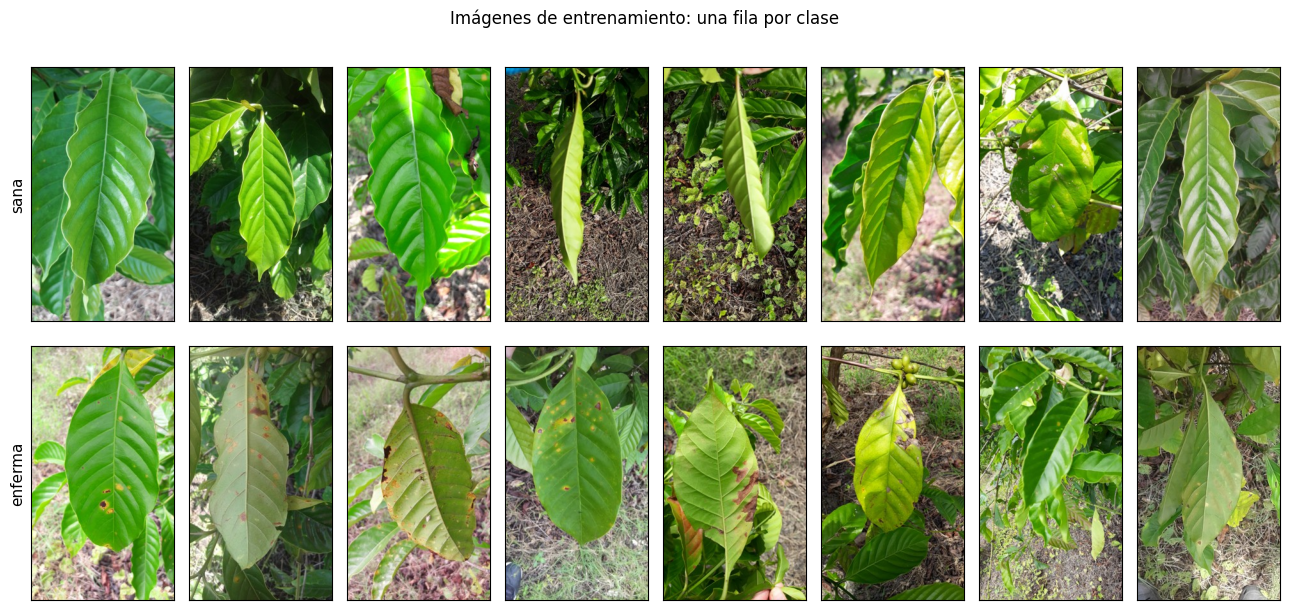

In [3]:
POR_FILA = 8
fig, ejes = plt.subplots(len(CLASES), POR_FILA, figsize=(13, 3.2 * len(CLASES)))
for c, clase in enumerate(CLASES):
    rutas = tabla.ruta[(tabla.clase == c) & (tabla.conjunto == "entrenamiento")].values[:POR_FILA]
    for k, ruta in enumerate(rutas):
        ax = ejes[c, k]
        ax.imshow(ImageOps.exif_transpose(Image.open(ruta)).convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(clase, fontsize=11)
plt.suptitle("Imágenes de entrenamiento: una fila por clase")
plt.tight_layout(); plt.show()

**Lectura:**
* Todas las fotos tienen el mismo formato: **vertical**, una hoja en el centro con la punta hacia arriba, tomadas en el cafetal con el fondo que hubiera (tierra, hojarasca, otras hojas, pasto).
* En las **enfermas** se ven manchas **amarillas, anaranjadas o cafés**, a veces grandes y a veces apenas dos o tres puntos. Varias enfermas, a primera vista, parecen sanas: la diferencia está en unos pocos píxeles. Es un problema mucho **más difícil** que perros contra gatos.
* Las clases están **balanceadas**: 300 y 300 para entrenar, 150 y 150 para la prueba. Adivinando siempre lo mismo se saca 50 %.

### Preparar las imágenes como las espera la red preentrenada
Las redes que vamos a usar aprendieron con **ImageNet**: 1,28 millones de fotos de 1 000 clases (más de 100 razas de perros, gatos, carros, tazas, hongos, volcanes...). Para que lo que aprendieron sirva, hay que darles las imágenes **igual que como las vieron al entrenar**:

1. **Tamaño:** cada foto (vertical, 225 × 400) se lleva a 180 × 320: mantiene la forma de la hoja sin recortar las puntas. Las redes convolucionales con *pooling* global aceptan imágenes que no son cuadradas.
2. **Escala:** de 0–255 a 0–1, igual que en el ejercicio 1.
3. **Normalizar con la media y la desviación de ImageNet:** a cada canal (rojo, verde, azul) se le resta su promedio en ImageNet (0,485; 0,456; 0,406) y se divide por su desviación (0,229; 0,224; 0,225). Es la misma idea de estandarizar las columnas de HIGGS en la semana 1, pero con los números **de ImageNet**, no los de nuestros datos: la red espera exactamente esa escala.

Guardamos todas las imágenes en memoria ya en su tamaño final, como enteros de 0 a 255. La normalización se hace lote por lote, justo antes de entrar a la red.

In [4]:
def leer(ruta):
    img = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")       # respetar la orientación del celular; 3 canales
    img = ImageOps.fit(img, (TAM_GUARDADO[1], TAM_GUARDADO[0]))          # recortar al centro y llevar a (ancho, alto)
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)    # (alto, ancho, 3) → (3, alto, ancho), enteros 0–255


t0 = time.time()
X = torch.stack([leer(r) for r in tabla.ruta])                           # todas las imágenes: (N, 3, alto, ancho)
y = torch.tensor(tabla.clase.values)
print(f"X: {tuple(X.shape)}, tipo {X.dtype}, {X.numel() / 1e6:.0f} MB en memoria  (leídas en {time.time() - t0:.0f} s)")

MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DISPOSITIVO).view(1, 3, 1, 1)   # de ImageNet
DESV = torch.tensor([0.229, 0.224, 0.225], device=DISPOSITIVO).view(1, 3, 1, 1)


def preparar(xb, aumento=False):
    x = xb.to(DISPOSITIVO).float() / 255                                 # 0–255 → 0–1
    if aumento:
        x = aumentar(x)                                                  # reto 1
    if tuple(x.shape[-2:]) != TAM_RED:
        x = F.interpolate(x, size=TAM_RED, mode="bilinear", align_corners=False)
    return (x - MEDIA) / DESV                                            # normalizar con los números de ImageNet


lote = preparar(X[:64])
print(f"Un lote listo para la red: {tuple(lote.shape)}")
print("Promedio por canal (R, G, B):", lote.mean(dim=(0, 2, 3)).cpu().numpy().round(2),
      "| desviación:", lote.std(dim=(0, 2, 3)).cpu().numpy().round(2))

X: (900, 3, 320, 180), tipo torch.uint8, 156 MB en memoria  (leídas en 1 s)
Un lote listo para la red: (64, 3, 320, 180)
Promedio por canal (R, G, B): [-0.35  0.23 -0.5 ] | desviación: [0.87 0.91 0.87]


### Un conjunto de prueba fijo y subconjuntos de entrenamiento anidados
* La **prueba** es siempre la misma para todos los modelos y todos los experimentos. No se toca para entrenar ni para decidir nada.
* Para entrenar con N imágenes por clase, tomamos las **primeras N** de una lista barajada una sola vez (semilla 42). Así, las 10 de N = 10 están dentro de las 25 de N = 25, que están dentro de las 50, etc. Cuando agregamos datos, **solo agregamos**: no cambiamos las fotos que ya estaban.
* Aquí no apartamos validación: con 10 imágenes por clase no alcanza para separar más. Todos los modelos entrenan un número fijo de pasos y se miden una sola vez en la prueba, al final.

In [5]:
PRUEBA = np.where(tabla.conjunto == "prueba")[0]
rng = np.random.default_rng(SEMILLA)
ORDEN = {c: rng.permutation(np.where((tabla.conjunto == "entrenamiento") & (tabla.clase == c))[0])
         for c in range(len(CLASES))}                                     # cada clase barajada una sola vez


def indices_entrenamiento(n):                                            # las primeras n imágenes de cada clase
    return np.concatenate([ORDEN[c][:n] for c in range(len(CLASES))])


print("Imágenes de prueba:", len(PRUEBA), "| disponibles para entrenar por clase:", min(len(o) for o in ORDEN.values()))
print("Con N = 10 por clase se entrena con", len(indices_entrenamiento(10)), "imágenes en total")

Imágenes de prueba: 300 | disponibles para entrenar por clase: 300
Con N = 10 por clase se entrena con 20 imágenes en total


## 2. Los competidores

| Competidor | Qué es | ¿Qué aprende? |
|---|---|---|
| **Desde cero** | Una CNN pequeña como las del ejercicio 1: 4 bloques de convolución 3 × 3 + max pooling, y una capa densa al final. Empieza con **pesos al azar**. | **Todo** |
| **Congelada** | **ResNet18** ya entrenada con ImageNet. Le quitamos su última capa (la que decide entre las 1 000 clases de ImageNet) y le ponemos una **cabeza nueva** para nuestras 2 clases. El resto queda **congelado**. | **Solo la cabeza nueva** |
| **Ajuste fino** (*fine-tuning*) | La misma ResNet18 con la cabeza nueva, pero **descongelamos el último bloque** de convoluciones (`layer4`) para que también se adapte, con una tasa de aprendizaje **10 veces más pequeña**. | La cabeza y el último bloque |

**¿Qué es ResNet18?** Una red convolucional de 18 capas (Microsoft Research, 2015). Su invento son los **atajos** (*skip connections*): cada bloque le **suma** su entrada a su salida. Así la señal y el gradiente pueden atravesar muchas capas sin apagarse, y por eso se pudieron entrenar redes de 50, 100 y hasta 152 capas. Es de las más usadas para transfer learning porque es pequeña y rápida.

**¿Qué quiere decir "congelar"?** Ponerle `requires_grad = False` a un parámetro: el `backward` no le calcula gradiente y el optimizador no lo mueve. La red congelada funciona como un **extractor de características**: convierte cada imagen en 512 números que describen lo que "ve" (bordes, texturas, partes de objetos, aprendidos con ImageNet), y la cabeza nueva aprende a decidir con esos 512 números. Es casi una regresión logística sobre las características de ImageNet.

**¿Por qué el ajuste fino usa una tasa más pequeña?** Los pesos de ResNet18 ya son buenos: costaron días de GPU y 1,28 millones de fotos. Si les damos pasos grandes (la tasa de 0,001 de la cabeza), con 20 fotos los destrozamos en pocos pasos y la red **olvida** lo que sabía (*olvido catastrófico*). Con 0,0001 se mueven poquito: se **ajustan** a nuestras imágenes sin olvidar. La cabeza nueva sí usa 0,001, porque empieza al azar.

Un detalle: las capas de **BatchNorm** (normalización por lotes, que tiene toda ResNet) guardan el promedio y la desviación de lo que vieron con ImageNet. En los modelos preentrenados las dejamos **fijas**: con lotes de 20 fotos, los promedios de cada lote son muy ruidosos.

In [6]:
def bloque(c_entra, c_sale):                     # convolución 3 × 3 → BatchNorm → ReLU → max pool 2 × 2
    return nn.Sequential(nn.Conv2d(c_entra, c_sale, kernel_size=3, padding=1), nn.BatchNorm2d(c_sale),
                         nn.ReLU(), nn.MaxPool2d(2))


def crear_desde_cero():
    return nn.Sequential(
        bloque(3, 32), bloque(32, 64), bloque(64, 128), bloque(128, 256),   # la imagen se encoge 16 veces; 256 mapas
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),          # promedio de cada mapa: 256 números por imagen
        nn.Dropout(0.3),
        nn.Linear(256, len(CLASES)))                    # la cabeza


ARQUITECTURAS = {  # nombre: (función que la construye, pesos aprendidos con ImageNet)
    "ResNet18":          (models.resnet18,           models.ResNet18_Weights.IMAGENET1K_V1),
    "ResNet50":          (models.resnet50,           models.ResNet50_Weights.IMAGENET1K_V2),
    "EfficientNet-B0":   (models.efficientnet_b0,    models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "MobileNetV3-Large": (models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.IMAGENET1K_V2),
    "VGG16":             (models.vgg16,              models.VGG16_Weights.IMAGENET1K_V1),
}


def cabeza_de(red):                                     # la última capa: la que decide la clase
    if isinstance(red, nn.Sequential):
        return red[-1]                                  # nuestra CNN desde cero
    return red.fc if hasattr(red, "fc") else red.classifier[-1]   # ResNet: .fc; las demás: .classifier[-1]


def ultimo_bloque_de(red):                              # el bloque de convoluciones más cercano a la salida
    if isinstance(red, nn.Sequential):
        return red[3]
    if hasattr(red, "layer4"):
        return red.layer4                               # ResNet
    if isinstance(red, models.VGG):
        return red.features[-7:]                        # VGG16: las 3 últimas convoluciones
    return red.features[-1]                             # EfficientNet y MobileNet


def crear_preentrenado(nombre="ResNet18", ajuste_fino=False):
    funcion, pesos = ARQUITECTURAS[nombre]
    red = funcion(weights=pesos)                        # la red con lo que aprendió en ImageNet
    for p in red.parameters():
        p.requires_grad = False                         # congelar todo
    nueva = nn.Linear(cabeza_de(red).in_features, len(CLASES))   # cabeza nueva, con pesos al azar: esta sí aprende
    if hasattr(red, "fc"):
        red.fc = nueva
    else:
        red.classifier[-1] = nueva
    if ajuste_fino:
        for p in ultimo_bloque_de(red).parameters():
            p.requires_grad = True                      # descongelar el último bloque
    return red


LR = 1e-3                                               # tasa de aprendizaje de la cabeza (y de toda la red desde cero)
COMPETIDORES = {
    "Desde cero":  dict(crear=crear_desde_cero, lr_cuerpo=LR, preentrenado=False),
    "Congelada":   dict(crear=lambda: crear_preentrenado("ResNet18"), lr_cuerpo=None, preentrenado=True),
    "Ajuste fino": dict(crear=lambda: crear_preentrenado("ResNet18", ajuste_fino=True), lr_cuerpo=LR / 10, preentrenado=True),
}


def contar(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    return total, entrenables


filas = []
for nombre, comp in COMPETIDORES.items():
    total, entrenables = contar(comp["crear"]())
    filas.append({"competidor": nombre, "parámetros en total": total, "parámetros que aprenden": entrenables,
                  "% que aprende": round(100 * entrenables / total, 2),
                  "tasa de la cabeza": LR, "tasa del cuerpo": comp["lr_cuerpo"] if comp["lr_cuerpo"] else "congelado"})
tabla_competidores = pd.DataFrame(filas).set_index("competidor")
tabla_competidores

,parámetros en total,parámetros que aprenden,% que aprende,tasa de la cabeza,tasa del cuerpo
competidor,,,,,
Desde cero,389890,389890,100.00,0.001,0.001
Congelada,11177538,1026,0.01,0.001,congelado
Ajuste fino,11177538,8394754,75.10,0.001,0.0001


**Lectura:**
* La CNN desde cero tiene **389 890** parámetros y los aprende **todos**, empezando al azar.
* ResNet18 tiene **11 177 538**, casi 29 veces más. Pero **congelada** solo aprende **1 026**: la cabeza nueva, 512 entradas × 2 clases + 2 sesgos. Es el **0,01 %** de la red. El resto ya viene aprendido de ImageNet.
* Con **ajuste fino** aprende **8 394 754** (75,1 %). El último bloque (`layer4`) tiene las tres cuartas partes de los parámetros: son las capas con más filtros (512).
* El número de parámetros **no depende del tamaño de la imagen**: las mismas cuentas sirven para fotos de 224 × 224 o de 320 × 180, porque un filtro es igual de grande donde sea que se pase. Por eso podemos usar fotos verticales con una red que se entrenó con fotos cuadradas.

### El ciclo de entrenamiento
Es el mismo ciclo del ejercicio 1, con tres cambios:
* **Dos tasas de aprendizaje:** el optimizador recibe dos grupos de parámetros, la cabeza (0,001) y el resto de lo que se puede entrenar (0,001 desde cero; 0,0001 en el ajuste fino).
* **Pasos en vez de épocas:** con 10 imágenes por clase, una época es **un solo lote**. Para que todos tengan oportunidad de aprender, cada entrenamiento hace **al menos 200 pasos de gradiente y al menos 10 épocas** (lo que dé más). Con pocos datos son muchas épocas: la red ve las mismas fotos cientos de veces.
* **Lotes de 32 imágenes**, cargados a la GPU de a uno (las imágenes viven en la memoria del computador).

In [15]:
def entrenar(competidor, idx, aumento=False, semilla=SEMILLA, pasos=None):
    torch.manual_seed(semilla)                                           # mismos pesos iniciales y mismo orden en cada corrida
    modelo = competidor["crear"]().to(DISPOSITIVO)
    cabeza = list(cabeza_de(modelo).parameters())
    en_cabeza = {id(p) for p in cabeza}
    cuerpo = [p for p in modelo.parameters() if p.requires_grad and id(p) not in en_cabeza]
    grupos = [{"params": cabeza, "lr": LR}]
    if cuerpo:                                                           # lo que no está congelado, con su propia tasa
        grupos.append({"params": cuerpo, "lr": competidor["lr_cuerpo"]})
    optimizador = torch.optim.AdamW(grupos, weight_decay=1e-4)
    perdida_fn = nn.CrossEntropyLoss()

    if pasos is None:
        pasos = max(PASOS_MIN, int(np.ceil(EPOCAS_MIN * len(idx) / LOTE)))
    generador = torch.Generator().manual_seed(semilla)
    modelo.train()
    if competidor["preentrenado"]:                                       # BatchNorm con las estadísticas de ImageNet
        for m in modelo.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
    t0, paso = time.time(), 0
    while paso < pasos:
        orden = torch.from_numpy(idx)[torch.randperm(len(idx), generator=generador)]   # barajar en cada época
        for i in range(0, len(orden), LOTE):
            if paso == pasos:
                break
            b = orden[i:i + LOTE]
            optimizador.zero_grad()                                      # 1. borrar los gradientes anteriores
            perdida = perdida_fn(modelo(preparar(X[b], aumento)), y[b].to(DISPOSITIVO))   # 2. forward y pérdida
            perdida.backward()                                           # 3. backward
            optimizador.step()                                           # 4. mover los pesos que no están congelados
            paso += 1
    if DISPOSITIVO == "cuda":
        torch.cuda.synchronize()
    return modelo, time.time() - t0


@torch.no_grad()                                                         # para predecir no hace falta guardar gradientes
def probabilidades(modelo, idx, lote=64):
    modelo.eval()
    return torch.cat([modelo(preparar(X[idx[i:i + lote]])).softmax(1).cpu() for i in range(0, len(idx), lote)])


def exactitud(modelo, idx):
    return (probabilidades(modelo, idx).argmax(1) == y[idx]).float().mean().item()

## Experimento 1 · La curva de pocos datos

Entrenamos los tres competidores con **10, 25, 50, 100, 200, 300 imágenes por clase** y medimos la exactitud en la misma prueba. Es la misma curva de **"exactitud según la cantidad de datos"** de HIGGS en la semana 1, pero ahora la pregunta es otra: no "¿ML o DL?", sino **"¿desde cero o con una red que ya sabe ver?"**.

Adivinando al azar se saca **50 %** (2 clases).

In [8]:
resultados, GUARDADOS = [], {}
t_exp = time.time()
for n in N_POR_CLASE:
    idx = indices_entrenamiento(n)
    linea = []
    for nombre, comp in COMPETIDORES.items():
        modelo, segundos = entrenar(comp, idx)
        acc = exactitud(modelo, PRUEBA)
        resultados.append({"imágenes por clase": n, "competidor": nombre, "exactitud (%)": 100 * acc, "segundos": segundos})
        linea.append(f"{nombre} {acc:.1%}")
        if n == N_FIJO:
            GUARDADOS[nombre] = modelo.cpu()                             # los guardamos para el experimento 3 y el reto 2
        del modelo
        liberar()
    print(f"{n:>4} por clase:  " + "   ".join(linea))
print(f"Experimento 1 listo en {time.time() - t_exp:.0f} s")
resultados = pd.DataFrame(resultados)

  10 por clase:  Desde cero 50.3%   Congelada 66.0%   Ajuste fino 67.7%
  25 por clase:  Desde cero 53.7%   Congelada 79.0%   Ajuste fino 83.3%
  50 por clase:  Desde cero 58.3%   Congelada 80.0%   Ajuste fino 85.0%
 100 por clase:  Desde cero 61.3%   Congelada 81.7%   Ajuste fino 88.7%
 200 por clase:  Desde cero 62.7%   Congelada 82.7%   Ajuste fino 89.0%
 300 por clase:  Desde cero 66.3%   Congelada 81.3%   Ajuste fino 91.0%
Experimento 1 listo en 110 s


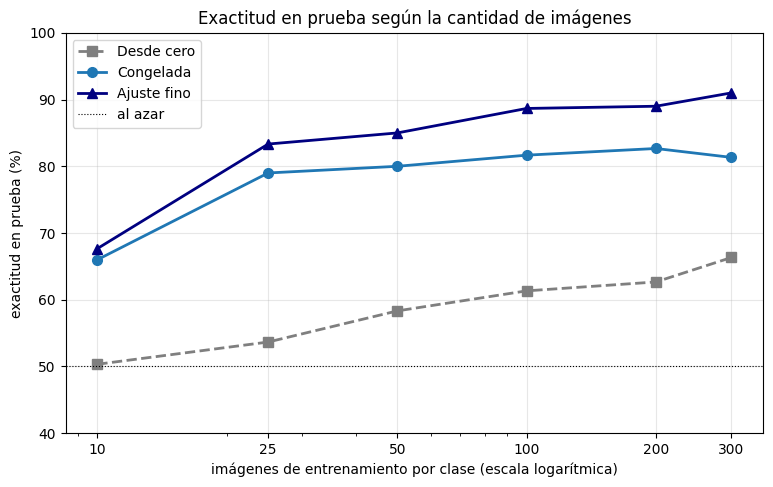

competidor,Desde cero,Congelada,Ajuste fino,ventaja del ajuste fino sobre desde cero (puntos)
imágenes por clase,,,,
10,50.3,66.0,67.7,17.3
25,53.7,79.0,83.3,29.7
50,58.3,80.0,85.0,26.7
100,61.3,81.7,88.7,27.3
200,62.7,82.7,89.0,26.3
300,66.3,81.3,91.0,24.7


In [9]:
ESTILO = {"Desde cero": ("s--", "tab:gray"), "Congelada": ("o-", "tab:blue"), "Ajuste fino": ("^-", "navy")}
plt.figure(figsize=(9, 5.2))
for nombre, (marca, color) in ESTILO.items():
    r = resultados[resultados.competidor == nombre]
    plt.plot(r["imágenes por clase"], r["exactitud (%)"], marca, color=color, lw=2, ms=7, label=nombre)
plt.axhline(100 / len(CLASES), color="black", lw=0.8, ls=":", label="al azar")
plt.xscale("log"); plt.xticks(N_POR_CLASE, N_POR_CLASE)
plt.xlabel("imágenes de entrenamiento por clase (escala logarítmica)"); plt.ylabel("exactitud en prueba (%)")
plt.ylim(0 if len(CLASES) > 2 else 40, 100); plt.grid(alpha=0.3); plt.legend()
plt.title("Exactitud en prueba según la cantidad de imágenes")
plt.show()

curva = resultados.pivot(index="imágenes por clase", columns="competidor", values="exactitud (%)")[list(COMPETIDORES)]
curva["ventaja del ajuste fino sobre desde cero (puntos)"] = curva["Ajuste fino"] - curva["Desde cero"]
curva.round(1)

**Lectura (el resultado más importante de la clase):**
* **Con 10 fotos por clase nadie hace milagros:** la CNN desde cero saca **50,3 %** (adivinar), la congelada **66,0 %** y el ajuste fino **67,7 %**. Con 20 hojas en total, ver dos o tres manchitas es muy difícil.
* **Con 25 por clase ya se nota todo:** el ajuste fino salta a **83,3 %**, la congelada a 79,0 % y la desde cero se queda en 53,7 %. Con **50** por clase: ajuste fino **85,0 %**, desde cero 58,3 %: **26,7 puntos** de ventaja.
* La CNN desde cero sube despacio y con 300 por clase llega a **66,3 %**: menos de lo que sacó el ajuste fino con **10**. Para aprender desde cero cómo es una mancha de roya, 600 fotos no alcanzan.
* **Aquí el ajuste fino le gana a la congelada, y cada vez por más:** la congelada se estanca alrededor de 81–83 % desde 100 por clase, mientras que el ajuste fino sigue subiendo hasta **91,0 %** con 300. La razón: **ImageNet no tiene hojas de café enfermas.** Las características que trae la red (bordes, texturas, partes de objetos) ayudan, pero no son exactamente las que hacen falta. Si se le deja ajustar el último bloque, aprende a fijarse en las manchas.
* Comparen con la versión de perros y gatos: allá la congelada ganaba, porque ImageNet sí trae perros y gatos. **Entre más lejos estén los datos de ImageNet, más importa el ajuste fino.**

## Experimento 2 · ¿Qué arquitectura? ¿Más grande es mejor?

Hay varias redes famosas entrenadas con ImageNet. Comparemos cinco, todas **congeladas** (solo aprende la cabeza nueva) y con **50 imágenes por clase**:

| Red | Año | Idea principal |
|---|---|---|
| **VGG16** | 2014 | 13 convoluciones de 3 × 3 apiladas + 3 capas densas enormes. Simple y pesada |
| **ResNet18** | 2015 | Los atajos (*skip connections*): cada bloque le suma su entrada a su salida. 18 capas |
| **ResNet50** | 2015 | La misma idea, con 50 capas y bloques "cuello de botella" (1 × 1 → 3 × 3 → 1 × 1) |
| **MobileNetV3-Large** | 2019 | Diseñada para celulares: convoluciones separables (primero cada canal por su lado, luego los mezcla), mucho más baratas |
| **EfficientNet-B0** | 2019 | Escala a la vez profundidad, ancho y resolución con una regla; muy buena exactitud por parámetro |

Para cada una medimos: parámetros, exactitud que tenía en ImageNet, segundos de entrenamiento, **milisegundos por imagen** al predecir (lo que importa en una app) y exactitud en nuestra prueba. Los tiempos dependen de la máquina y de qué más esté corriendo en ella: compárenlos entre sí, no con los de otro computador.

VGG16 tiene **138 millones** de parámetros (134 millones cuando le cambiamos la cabeza de 1 000 clases por la de 2) y MobileNetV3, unos **5 millones**.

In [10]:
@torch.no_grad()
def milisegundos_por_imagen(modelo, n=64, repeticiones=10):
    modelo.eval()
    x = preparar(X[PRUEBA[:n]])
    modelo(x)                                                            # calentar (la primera vez siempre es más lenta)
    tiempos = []
    for _ in range(repeticiones):
        if DISPOSITIVO == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        modelo(x)
        if DISPOSITIVO == "cuda":
            torch.cuda.synchronize()
        tiempos.append(time.time() - t0)
    return 1000 * min(tiempos) / n                                       # la más rápida: la menos afectada por otros programas


idx = indices_entrenamiento(N_FIJO)
filas = []
t_exp = time.time()
for nombre, (funcion, pesos) in ARQUITECTURAS.items():
    comp = dict(crear=lambda nombre=nombre: crear_preentrenado(nombre), lr_cuerpo=None, preentrenado=True)
    modelo, segundos = entrenar(comp, idx)
    total, entrenables = contar(modelo)
    filas.append({"red": nombre, "parámetros (millones)": total / 1e6, "aprenden (miles)": entrenables / 1e3,
                  "exactitud en ImageNet (%)": pesos.meta["_metrics"]["ImageNet-1K"]["acc@1"],
                  "segundos de entrenamiento": segundos, "ms por imagen": milisegundos_por_imagen(modelo),
                  "exactitud aquí (%)": 100 * exactitud(modelo, PRUEBA)})
    print(f"{nombre}: {filas[-1]['exactitud aquí (%)']:.1f} %")
    del modelo
    liberar()
print(f"Experimento 2 listo en {time.time() - t_exp:.0f} s")
arquitecturas = pd.DataFrame(filas).set_index("red")
arquitecturas.round(2)

ResNet18: 80.0 %
ResNet50: 80.0 %
EfficientNet-B0: 75.3 %
MobileNetV3-Large: 76.3 %
VGG16: 77.3 %
Experimento 2 listo en 46 s


,parámetros (millones),aprenden (miles),exactitud en ImageNet (%),segundos de entrenamiento,ms por imagen,exactitud aquí (%)
red,,,,,,
ResNet18,11.18,1.03,69.76,3.43,0.57,80.00
ResNet50,23.51,4.10,80.86,8.71,1.64,80.00
EfficientNet-B0,4.01,2.56,77.69,4.69,0.72,75.33
MobileNetV3-Large,4.20,2.56,75.27,2.87,0.41,76.33
VGG16,134.27,8.19,71.59,17.08,3.09,77.33


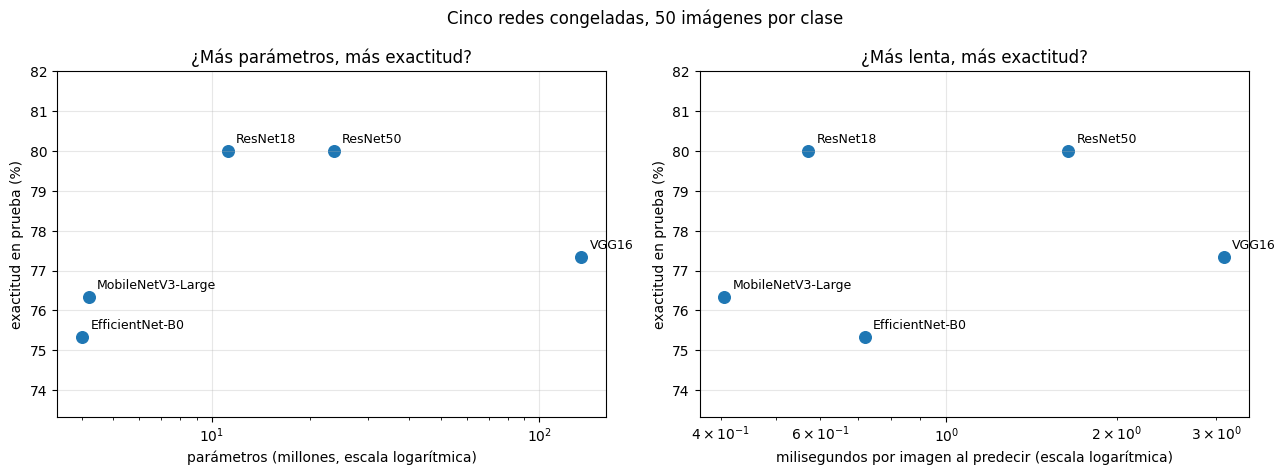

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, columna, etiqueta in [(ejes[0], "parámetros (millones)", "parámetros (millones, escala logarítmica)"),
                              (ejes[1], "ms por imagen", "milisegundos por imagen al predecir (escala logarítmica)")]:
    ax.scatter(arquitecturas[columna], arquitecturas["exactitud aquí (%)"], s=70, color="tab:blue")
    for red, fila in arquitecturas.iterrows():
        ax.annotate(red, (fila[columna], fila["exactitud aquí (%)"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
    ax.set_xscale("log"); ax.set_xlabel(etiqueta); ax.set_ylabel("exactitud en prueba (%)"); ax.grid(alpha=0.3)
    lo, hi = arquitecturas["exactitud aquí (%)"].min(), arquitecturas["exactitud aquí (%)"].max()
    ax.set_ylim(lo - max(2, (hi - lo) * 0.4), min(100.5, hi + max(2, (hi - lo) * 0.4)))
ejes[0].set_title("¿Más parámetros, más exactitud?"); ejes[1].set_title("¿Más lenta, más exactitud?")
plt.suptitle(f"Cinco redes congeladas, {N_FIJO} imágenes por clase")
plt.tight_layout(); plt.show()

**Lectura:**
* **Ninguna red congelada pasa de 80 %:** ResNet18 y ResNet50 empatan en **80,0 %**, VGG16 saca 77,3 %, MobileNetV3 76,3 % y EfficientNet-B0 **75,3 %**. Todas quedan por debajo del ajuste fino de ResNet18 con las mismas 50 fotos por clase (85,0 %, experimento 1).
* **¿Más grande es mejor? No.** VGG16 tiene **134 millones** de parámetros y queda tercera. ResNet50 tiene el doble de parámetros que ResNet18 y **empata** con ella.
* **La que más sabía de ImageNet no es la mejor aquí:** EfficientNet-B0 es la segunda mejor en ImageNet (77,7 %) y la **última** en hojas de café. Lo que una red aprendió para separar 1 000 clases de objetos no se traslada igual a manchas en hojas: cuando los datos son de otro mundo, **hay que probar**, no se puede adivinar por la tabla de ImageNet.
* **La velocidad sí sigue al tamaño:** VGG16 tarda **3,64 ms** por imagen y 20 s en entrenar; MobileNetV3, **0,49 ms** (7 veces más rápida) y 6 s. Para una app que corre en el celular del caficultor, MobileNetV3 perdiendo 3,7 puntos puede ser mejor negocio que ResNet50.

## Experimento 3 · ¿Dónde mira el modelo? Grad-CAM

Que la red acierte no quiere decir que acierte **por la razón correcta**. Un caso famoso: un modelo que "distinguía" lobos de perros husky en realidad miraba si había **nieve en el fondo**. A eso se le llama ***shortcut learning*** (aprender por el atajo): la red encuentra una pista fácil que funciona en los datos de entrenamiento pero no es lo que nos importa.

**Grad-CAM** (*Gradient-weighted Class Activation Mapping*, 2017) pinta un mapa de calor sobre la imagen con las zonas que más empujaron la decisión. La receta:
1. Pasamos la imagen y guardamos los **mapas de características** del último bloque convolucional (en ResNet18, con las fotos de 320 × 180 de este cuaderno, 512 mapas de 10 × 6).
2. Hacemos `backward` desde el **puntaje de la clase que eligió** la red y guardamos el gradiente de esos mapas: dice cuánto subiría el puntaje si cada mapa se encendiera un poco más.
3. El promedio del gradiente de cada mapa es su **importancia**. Sumamos los mapas multiplicados por su importancia, nos quedamos con lo positivo (ReLU) y lo ampliamos al tamaño de la imagen.

Para "espiar" lo que pasa dentro de la red sin cambiarla usamos ***hooks*** (ganchos): funciones que PyTorch llama cada vez que una capa produce su salida.

Comparamos dos modelos entrenados con **50 imágenes por clase** (los del experimento 1): el **ajuste fino** y el **desde cero**. Arriba de cada foto: la clase real y lo que dijo el ajuste fino.

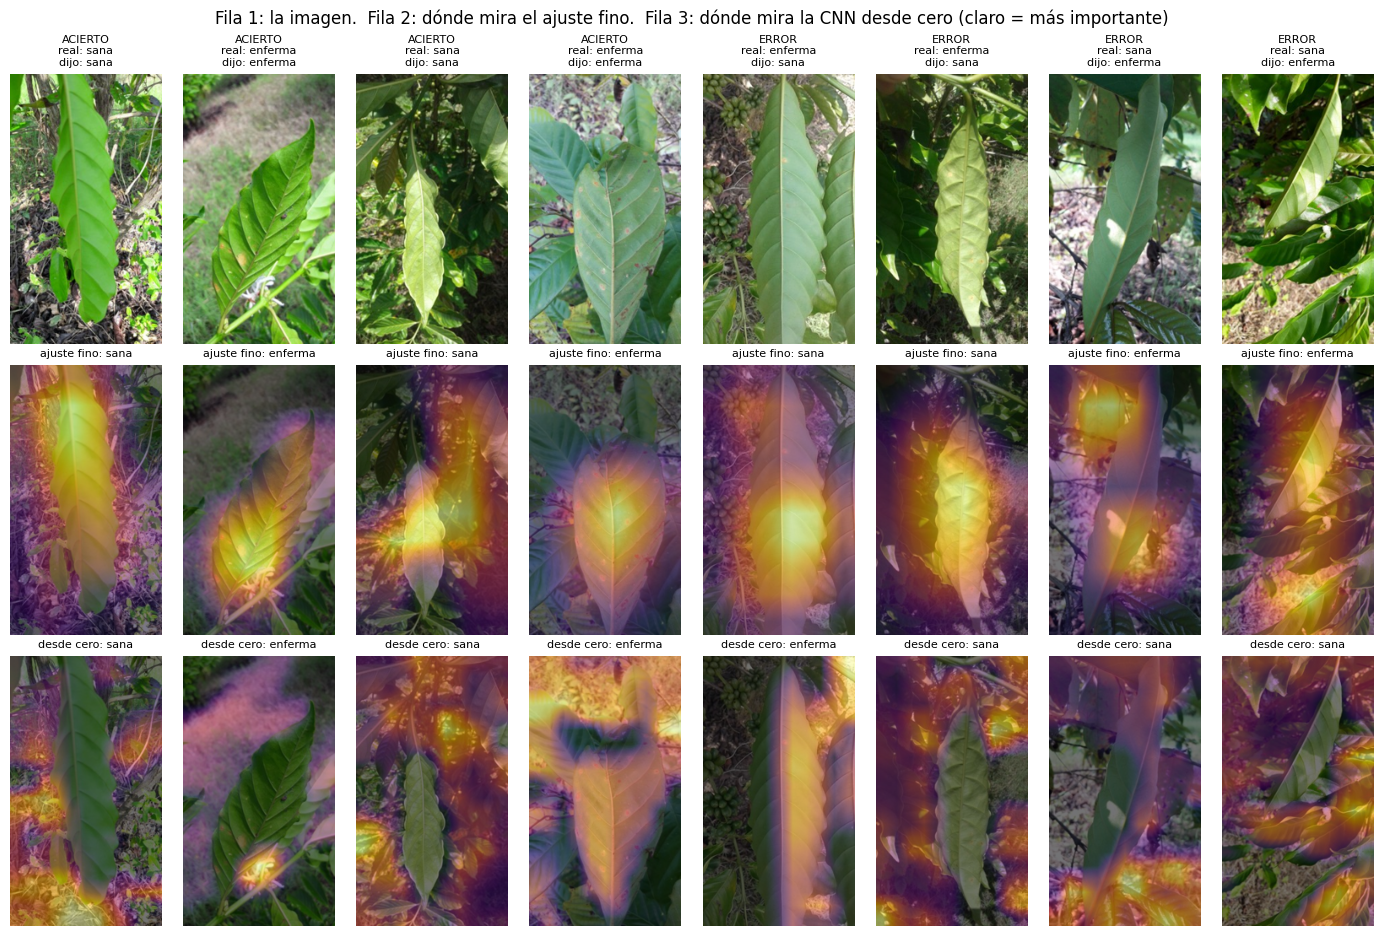

El ajuste fino se equivoca en 45 de 300 imágenes de prueba


In [12]:
def grad_cam(modelo, capa, x):
    guardado = {}

    def gancho(modulo, entrada, salida):                                 # se llama cuando la capa produce su salida
        guardado["mapas"] = salida
        salida.register_hook(lambda g: guardado.__setitem__("gradientes", g))   # y esto, en el backward

    h = capa.register_forward_hook(gancho)
    modelo.eval()
    x = x.clone().requires_grad_(True)                                   # para que haya gradiente aunque la red esté congelada
    puntajes = modelo(x)
    clase = puntajes.argmax(1).item()
    modelo.zero_grad()
    puntajes[0, clase].backward()                                        # gradiente del puntaje de la clase elegida
    h.remove()
    importancia = guardado["gradientes"].mean(dim=(2, 3), keepdim=True)  # un número por mapa
    cam = F.relu((importancia * guardado["mapas"]).sum(1, keepdim=True)) # suma ponderada; solo lo que empuja a favor
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu(), clase


def para_ver(i):                                                         # la imagen i como (alto, ancho, 3) entre 0 y 1
    x = X[i:i + 1].float() / 255
    if tuple(x.shape[-2:]) != TAM_RED:
        x = F.interpolate(x, size=TAM_RED, mode="bilinear", align_corners=False)
    return x[0].permute(1, 2, 0).numpy()


fino = GUARDADOS["Ajuste fino"].to(DISPOSITIVO)
cero = GUARDADOS["Desde cero"].to(DISPOSITIVO)
prob_fino = probabilidades(fino, PRUEBA)
pred_fino = prob_fino.argmax(1)
acierta = (pred_fino == y[PRUEBA]).numpy()
seguridad = prob_fino.max(1).values.numpy()
aciertos_por_clase = [PRUEBA[acierta & (y[PRUEBA].numpy() == c)] for c in range(len(CLASES))]
bien = np.array([aciertos_por_clase[k % len(CLASES)][k // len(CLASES)] for k in range(4)])   # 4 aciertos, de clases distintas
mal = PRUEBA[~acierta][np.argsort(-seguridad[~acierta])][:4]              # los 4 errores en que estaba más segura
elegidas = np.concatenate([bien, mal])

fig, ejes = plt.subplots(3, len(elegidas), figsize=(14, 6.3 if TAM_RED[0] == TAM_RED[1] else 9.5))
for k, i in enumerate(elegidas):
    imagen = para_ver(i)
    x = preparar(X[i:i + 1])
    for fila, (modelo, capa, titulo) in enumerate([(fino, fino.layer4, "ajuste fino"), (cero, cero[3], "desde cero")], start=1):
        cam, clase = grad_cam(modelo, capa, x)
        ejes[fila, k].imshow(imagen)
        ejes[fila, k].imshow(cam, cmap="inferno", alpha=0.55)
        ejes[fila, k].set_title(f"{titulo}: {CLASES[clase]}", fontsize=8)
    ejes[0, k].imshow(imagen)
    ejes[0, k].set_title(f"{'ACIERTO' if k < len(bien) else 'ERROR'}\nreal: {CLASES[y[i]]}\ndijo: {CLASES[pred_fino[list(PRUEBA).index(i)]]}", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
plt.suptitle("Fila 1: la imagen.  Fila 2: dónde mira el ajuste fino.  Fila 3: dónde mira la CNN desde cero (claro = más importante)")
plt.tight_layout(); plt.show()
print(f"El ajuste fino se equivoca en {(~acierta).sum()} de {len(PRUEBA)} imágenes de prueba")

**Lectura:**
* **El ajuste fino mira la hoja.** En casi todas las fotos el mapa se enciende sobre la hoja del centro, que es donde está (o no está) la enfermedad.
* **La CNN desde cero mira el fondo:** la tierra, la hojarasca, el pasto, las hojas de atrás, los racimos de café. En varias fotos la hoja del centro queda **apagada**. Esto es ***shortcut learning*** en vivo: con 100 fotos, la red encontró pistas en el fondo que le sirven un poco en esas fotos (quizás las hojas enfermas se fotografiaron en otros lotes, con otra luz o en otro tipo de suelo), pero no tienen nada que ver con la roya. Por eso no pasa de 58 %.
* **En los errores, el ajuste fino también mira la hoja, pero no encuentra las manchas:** en las dos enfermas que dijo "sana", a este tamaño casi no se ven manchas. Y en las dos sanas que dijo "enferma", el mapa se va hacia una zona clara o hacia las hojas de atrás.
* Un modelo que acierta mirando el fondo **funcionaría en las fotos de este conjunto y fallaría en otra finca**. Grad-CAM sirve para darse cuenta antes de ponerlo a funcionar.

## Cierre: ¿desde cero, congelar o ajustar?

**La regla:** si tienen **pocas imágenes** y se parecen a las fotos de ImageNet (objetos, animales, cosas del día a día), **congelen** una red preentrenada y entrenen solo la cabeza. Si tienen **cientos de imágenes** o se parecen poco a ImageNet (hojas enfermas, satélite, rayos X), hagan **ajuste fino** del último bloque con una tasa pequeña. **Desde cero**, solo con decenas de miles de imágenes o cuando no hay ninguna red preentrenada que se parezca a sus datos.

| Enfoque | Qué aprende | Parámetros que aprenden | Tasa | 10 por clase | 50 por clase | 300 por clase | Cuándo |
|---|---|---|---|---|---|---|---|
| **Desde cero** | Todo, desde pesos al azar | 389 890 (todos) | 0,001 | 50,3 % | 58,3 % | 66,3 % | Muchísimos datos, o imágenes que no se parecen a ninguna foto |
| **Congelada** (ResNet18) | Solo la cabeza nueva | 1 026 (0,01 %) | 0,001 | 66,0 % | 80,0 % | 81,3 % | Pocos datos, parecidos a ImageNet. Lo más rápido y barato |
| **Ajuste fino** (ResNet18) | Cabeza + último bloque | 8 394 754 (75 %) | 0,0001 en el cuerpo | **67,7 %** | **85,0 %** | **91,0 %** | Más datos, o datos distintos a ImageNet (este caso) |

**Una analogía.** Entrenar desde cero es como contratar a alguien que nunca ha visto una planta y pedirle que aprenda a reconocer la roya con 20 fotos. Congelar es contratar a un **fotógrafo experto**: sabe mirar formas, texturas y colores, y solo le explicamos qué fotos son "sana" y cuáles "enferma"; no cambia su forma de mirar. El ajuste fino es mandar a ese fotógrafo **una temporada con un agrónomo de Cenicafé**: afina el ojo para las manchas, sin olvidar lo que ya sabía (por eso la tasa pequeña).

Con la diferencia de que el "ojo" de la red son 11 millones de números aprendidos con fotos de objetos, no de hojas: con perros y gatos le servía casi tal cual, pero con hojas de café solo le sirve a medias, y por eso aquí el ajuste fino le saca **10 puntos** a la congelada con 300 fotos por clase.

### ¿Dónde se usa esto?
* **Apps para el agricultor:** hay apps gratuitas (como *Plantix*) que diagnostican enfermedades de cultivos con una foto del celular, y grupos de investigación en Colombia y Brasil han publicado modelos para detectar roya en café. Casi todos parten de una red preentrenada en ImageNet, porque nadie tiene millones de fotos de hojas.
* **Drones y cámaras en el cultivo:** la misma idea, aplicada a fotos aéreas de los lotes, sirve para encontrar focos de roya antes de que se extiendan.
* **El límite real no es la red, son las etiquetas:** cada foto de RoCoLe la tuvo que revisar alguien que sabe de café. Con transfer learning, un centro de investigación puede arrancar un proyecto con unas cientos de fotos etiquetadas en vez de decenas de miles.

## Retos para entregar

Son **4 retos**. Los retos 1 y 2 usan celdas que ya están abajo (aumento de datos y errores del modelo); los retos 3 y 4 piden código nuevo, que les damos casi listo.

**Cómo entregar:** al final del cuaderno, una sección por reto (`### Reto 1` … `### Reto 4`) con el código, su salida y una celda de texto con las respuestas.

**Antes de empezar:** corran el cuaderno completo una vez, de arriba abajo. Los retos usan `crear_preentrenado`, `entrenar`, `exactitud`, `contar`, `indices_entrenamiento`, `COMPETIDORES`, `PRUEBA` y `LR`, que ya quedaron creados.

### Cómo se responden las preguntas

Describir lo que salió no basta: hay que explicar **por qué** salió así. Cada respuesta tiene cuatro partes:
1. **El dato**, con su número.
2. **¿Es real o es ruido?** Con 300 fotos de prueba, 1 foto = 0,33 puntos y el ruido es de ± 2 a 3 puntos.
3. **La causa:** qué en los datos, el modelo o el entrenamiento lo explica.
4. **Qué harían** con eso.

Ejemplo con el experimento 1:
- **Descripción (no sirve):** «La congelada sacó 81,3 % con 300 imágenes por clase.»
- **Análisis (sí sirve):** «La congelada se estanca entre 80 y 83 % desde 25 por clase; la bajada de 82,7 a 81,3 son 4 fotos, o sea ruido. Se estanca porque solo entrena 1.026 parámetros sobre 512 características **fijas** de ImageNet: más fotos no cambian lo que puede ver. Para pasar de ahí hay que dejar que el último bloque se adapte, que es el ajuste fino.»

---

### Reto 1 · Aumento de datos

El **aumento de datos** (*data augmentation*) le aplica a cada imagen, **cada vez que entra a la red**, un cambio al azar que no cambia su clase. La regla: **solo cambios que podrían pasar en la vida real** con la misma clase. Para hojas de café:
* **voltear de izquierda a derecha:** sí. **De arriba a abajo no:** en todas las fotos la hoja está con la punta hacia arriba;
* **brillo y contraste ± 15 %:** sí (sol, nube, sombra);
* **recortar:** no. Una hoja con roya leve tiene dos o tres manchas, y un recorte las puede dejar por fuera;
* **saturación y tono:** no. La enfermedad **es** un cambio de color.

Así se ven 8 versiones aumentadas de la misma imagen:

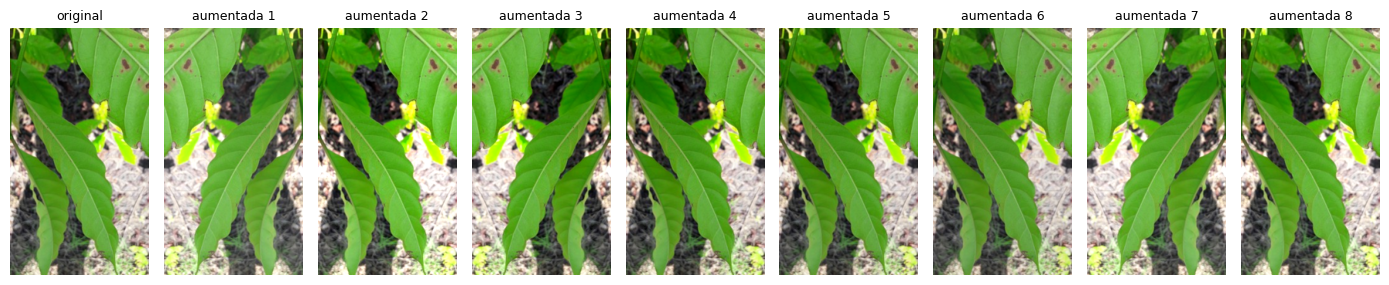

In [13]:
AUMENTO = dict(volteo_horizontal=True, volteo_vertical=False, giros_90=False,
               recorte_min=1.0, brillo=0.15, contraste=0.15, saturacion=0.0)


def aumentar(x):                                                         # x: lote (B, 3, alto, ancho) entre 0 y 1, en la GPU
    B, dev = len(x), x.device

    def al_azar(p=0.5):                                                  # True con probabilidad p, una por imagen
        return (torch.rand(B, device=dev) < p).view(B, 1, 1, 1)

    if AUMENTO["volteo_horizontal"]:
        x = torch.where(al_azar(), x.flip(3), x)
    if AUMENTO["volteo_vertical"]:
        x = torch.where(al_azar(), x.flip(2), x)
    if AUMENTO["giros_90"]:                                              # 0°, 90°, 180° o 270° (solo imágenes cuadradas)
        vueltas = torch.randint(0, 4, (B,))
        x = torch.stack([torch.rot90(x[i], int(vueltas[i]), dims=(1, 2)) for i in range(B)])
    if AUMENTO["recorte_min"] < 1:                                       # recortar un pedazo y volverlo a ampliar
        lado = torch.empty(B, device=dev).uniform_(AUMENTO["recorte_min"], 1)        # fracción del lado que se conserva
        corre_x = (torch.rand(B, device=dev) * 2 - 1) * (1 - lado)
        corre_y = (torch.rand(B, device=dev) * 2 - 1) * (1 - lado)
        theta = torch.zeros(B, 2, 3, device=dev)
        theta[:, 0, 0], theta[:, 1, 1], theta[:, 0, 2], theta[:, 1, 2] = lado, lado, corre_x, corre_y
        x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), align_corners=False)

    def factor(a):                                                       # un número entre 1 − a y 1 + a, uno por imagen
        return 1 + a * (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1)

    if AUMENTO["brillo"]:
        x = x * factor(AUMENTO["brillo"])
    if AUMENTO["contraste"]:
        m = x.mean(dim=(1, 2, 3), keepdim=True)
        x = m + (x - m) * factor(AUMENTO["contraste"])
    if AUMENTO["saturacion"]:
        gris = x.mean(1, keepdim=True)
        x = gris + (x - gris) * factor(AUMENTO["saturacion"])
    return x.clamp(0, 1)


torch.manual_seed(0)
i = indices_entrenamiento(N_FIJO)[0]
original = X[i:i + 1].float().to(DISPOSITIVO) / 255
versiones = aumentar(original.repeat(8, 1, 1, 1)).cpu()
fig, ejes = plt.subplots(1, 9, figsize=(14, 2.2 if TAM_RED[0] == TAM_RED[1] else 3.4))
ejes[0].imshow(original[0].cpu().permute(1, 2, 0)); ejes[0].set_title("original", fontsize=9)
for k in range(8):
    ejes[k + 1].imshow(versiones[k].permute(1, 2, 0)); ejes[k + 1].set_title(f"aumentada {k + 1}", fontsize=9)
for ax in ejes:
    ax.axis("off")
plt.tight_layout(); plt.show()

Ahora entrenamos la CNN **desde cero** y el **ajuste fino** con las mismas 50 imágenes por clase, **sin y con aumento**. Con aumento la tarea es más difícil (la red nunca ve la misma foto dos veces), así que a los cuatro entrenamientos les damos **el doble de pasos** que en el experimento 1. Por eso los resultados sin aumento no son exactamente los del experimento 1.

400 pasos por entrenamiento
Experimento 4 listo en 53 s


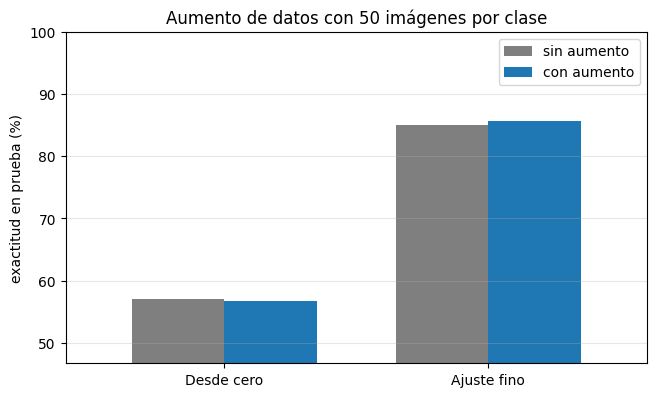

,sin aumento,con aumento,cambio (puntos)
competidor,,,
Desde cero,57.0,56.7,-0.3
Ajuste fino,85.0,85.7,0.7


In [14]:
idx = indices_entrenamiento(N_FIJO)
PASOS_AUMENTO = 2 * max(PASOS_MIN, int(np.ceil(EPOCAS_MIN * len(idx) / LOTE)))     # el doble que en el experimento 1
filas = []
t_exp = time.time()
for nombre in ["Desde cero", "Ajuste fino"]:
    fila = {"competidor": nombre}
    for aumento in [False, True]:
        modelo, _ = entrenar(COMPETIDORES[nombre], idx, aumento=aumento, pasos=PASOS_AUMENTO)
        fila["con aumento" if aumento else "sin aumento"] = 100 * exactitud(modelo, PRUEBA)
        del modelo
        liberar()
    filas.append(fila)
print(f"{PASOS_AUMENTO} pasos por entrenamiento")
print(f"Reto 1 listo en {time.time() - t_exp:.0f} s")
tabla_aumento = pd.DataFrame(filas).set_index("competidor")
tabla_aumento["cambio (puntos)"] = tabla_aumento["con aumento"] - tabla_aumento["sin aumento"]

ax = tabla_aumento[["sin aumento", "con aumento"]].plot.bar(figsize=(7.5, 4.3), rot=0, color=["tab:gray", "tab:blue"], width=0.7)
ax.set_ylim(max(0, tabla_aumento.values[:, :2].min() - 10), 100)
ax.set_ylabel("exactitud en prueba (%)"); ax.set_xlabel(""); ax.grid(axis="y", alpha=0.3)
ax.set_title(f"Aumento de datos con {N_FIJO} imágenes por clase"); plt.show()
tabla_aumento.round(1)

**Qué tienen que hacer:**
1. Corran las dos celdas de este reto tal como están (`AUMENTO` y la de entrenamiento) y anoten `tabla_aumento`.
2. En el diccionario `AUMENTO` de la primera celda cambien **una sola cosa**, vuelvan a correr las dos celdas y anoten la tabla. Hagan dos pruebas, volviendo a la configuración original entre una y otra:
   - **(a)** `recorte_min=0.8` (recortar entre el 80 % y el 100 % del lado);
   - **(b)** `saturacion=0.3` (cambiar los colores ± 30 %).
3. Al terminar, dejen `AUMENTO` como estaba y corran otra vez la celda.

**Qué entregan:**

| configuración | desde cero sin aumento | desde cero con aumento | ajuste fino sin aumento | ajuste fino con aumento |
|---|---|---|---|---|
| original | | | | |
| (a) + recorte | | | | |
| (b) + saturación | | | | |

**Qué responden:**
1. **Con la configuración original, ¿el aumento ayudó?** Pasen la diferencia a número de fotos y digan si es más grande que el ruido. Expliquen **por qué**: ¿qué le muestra a la red voltear una hoja o cambiarle el brillo, y qué es lo que de verdad le falta para reconocer la roya?
2. **¿Qué pasó con (a) y con (b)?** Expliquen el mecanismo: qué le hace cada cambio a la evidencia de la enfermedad, y qué aprende la red cuando la imagen ya no corresponde a su etiqueta.
3. **¿El aumento le sirve igual a la red desde cero que al ajuste fino?** Explíquenlo con lo que **ya sabe** cada una antes de entrenar.

---

### Reto 2 · Errores: precisión, exhaustividad y umbral

Miramos en detalle el **ajuste fino con 50 imágenes por clase**:
* **Precisión** de «enferma»: de las veces que la red dijo «enferma», ¿cuántas lo eran? Importa cuando una falsa alarma cuesta (fumigar una hoja sana).
* **Exhaustividad** (*recall*) de «enferma»: de todas las enfermas, ¿cuántas encontró? Importa cuando dejar pasar un caso cuesta (una hoja con roya que sigue regando esporas).
* **F1:** el promedio armónico de las dos.

In [ ]:
pred = pred_fino.numpy()
real = y[PRUEBA].numpy()
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay(confusion_matrix(real, pred), display_labels=CLASES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_xlabel("lo que dijo la red"); ax.set_ylabel("clase real")
ax.set_title(f"Ajuste fino ({N_FIJO} por clase): matriz de confusión en {len(PRUEBA)} imágenes de prueba")
plt.show()

reporte = pd.DataFrame(classification_report(real, pred, target_names=CLASES, output_dict=True)).T
reporte = reporte.rename(columns={"precision": "precisión", "recall": "exhaustividad", "f1-score": "F1", "support": "imágenes"})
reporte.loc[CLASES].round(3)

Y los errores mismos, empezando por los que la red estaba **más segura**. Arriba de cada imagen: la clase real, lo que dijo y con qué probabilidad.

In [ ]:
errores = PRUEBA[~acierta][np.argsort(-seguridad[~acierta])]
cuantos = min(16, len(errores))
fig, ejes = plt.subplots(2, 8, figsize=(14, 7.4))
for ax in ejes.flat:
    ax.axis("off")
for ax, i in zip(ejes.flat, errores[:cuantos]):
    k = list(PRUEBA).index(i)
    ax.imshow(para_ver(i))
    ax.set_title(f"real: {CLASES[y[i]]}\ndijo: {CLASES[pred_fino[k]]} ({prob_fino[k].max():.0%})", fontsize=8)
plt.suptitle(f"Los {cuantos} errores más seguros del ajuste fino (de {len(errores)} errores en {len(PRUEBA)} imágenes)")
plt.tight_layout(); plt.show()

**Qué tienen que hacer:**
1. Corran las dos celdas de este reto: la matriz de confusión con su tabla, y los errores más seguros.
2. **Calculen a mano**, desde la matriz, la precisión y la exhaustividad de «enferma». Muestren la cuenta.
3. **Bajen el umbral.** Hoy la red dice «enferma» desde 50 %. Agreguen esta celda, que compara 0,5 con 0,3:
   ```python
   k = CLASES.index("enferma")
   for umbral in [0.5, 0.3]:
       pred_u = (prob_fino[:, k] >= umbral).long().numpy()      # 1 = "enferma", 0 = "sana"
       vn, fp, fn, vp = confusion_matrix(real, pred_u).ravel()
       rep = classification_report(real, pred_u, target_names=CLASES, output_dict=True)["enferma"]
       print(f"umbral {umbral}: se escapan {fn}, falsas alarmas {fp}, "
             f"precisión {rep['precision']:.3f}, exhaustividad {rep['recall']:.3f}")
   ```

**Qué entregan:** la matriz 2 × 2, la cuenta a mano y esta tabla.

| umbral | enfermas que se escapan | falsas alarmas | precisión de «enferma» | exhaustividad de «enferma» |
|---|---|---|---|---|
| 0,5 | | | | |
| 0,3 | | | | |

**Qué responden:**
1. **¿Los errores van en las dos direcciones por igual?** Si no, expliquen **por qué**: piensen en cómo se ve una hoja con roya leve reducida a 180 × 320, y miren qué tienen en común los errores más seguros.
2. **En una finca, ¿qué error cuesta más?** Con eso, ¿qué medida vigilarían, y por qué la exactitud (cerca de 85 %) no alcanza para decidir si el modelo sirve?
3. **Con umbral 0,3, ¿qué pasó?** Expliquen por qué la precisión y la exhaustividad se mueven en sentidos contrarios. ¿Qué umbral escogerían, y con qué datos lo escogerían en un proyecto real? ¿Está bien escogerlo mirando la prueba?

---

### Reto 3 · Descongelar más

El ajuste fino del cuaderno descongela **solo el último bloque** (`layer4` en ResNet18). ¿Y si descongelamos **toda la red**?

**Qué tienen que hacer:**
1. Agreguen esta celda. Entrena «solo layer4» (el del cuaderno, para comparar) y «toda la red», cada uno con dos tasas para el cuerpo (`LR / 10` = 0,0001, la del cuaderno, y `LR` = 0,001, la de la cabeza) y con 10 y 300 imágenes por clase. Son 8 entrenamientos:
   ```python
   def crear_descongelada(cuanto):
       red = crear_preentrenado("ResNet18", ajuste_fino=True)      # ya viene con layer4 descongelado
       if cuanto == "toda la red":
           for p in red.parameters():
               p.requires_grad = True
       return red

   filas = []
   for cuanto in ["solo layer4", "toda la red"]:
       for lr_cuerpo in [LR / 10, LR]:
           comp = dict(crear=lambda cuanto=cuanto: crear_descongelada(cuanto), lr_cuerpo=lr_cuerpo, preentrenado=True)
           for n in [10, 300]:
               modelo, _ = entrenar(comp, indices_entrenamiento(n))
               filas.append({"descongelado": cuanto, "tasa del cuerpo": lr_cuerpo, "imágenes por clase": n,
                             "aprenden": contar(modelo)[1], "exactitud (%)": 100 * exactitud(modelo, PRUEBA)})
               del modelo
               liberar()
   pd.DataFrame(filas)
   ```

**Qué entregan:**

| descongelado | tasa del cuerpo | parámetros que aprenden | exactitud con 10 por clase (%) | exactitud con 300 por clase (%) |
|---|---|---|---|---|

**Qué responden:**
1. **¿Descongelar toda la red ayuda o empeora, con 10 y con 300 por clase?** Expliquen **por qué**, con lo que aprendió cada capa en ImageNet (las primeras, cosas generales; las últimas, específicas) y con cuántos parámetros hay que ajustar con 20 o con 600 fotos.
2. **¿Qué pasa con la tasa de 0,001 en el cuerpo?** Expliquen qué les pasa a los pesos preentrenados con pasos grandes.

---

### Reto 4 · Tres semillas

Con 10 imágenes por clase, el resultado depende mucho de **cuáles** 10 fotos le tocaron a la red. Dos cosas dependen de `SEMILLA = 42`: `ORDEN` (qué fotos le tocan a cada N) y `entrenar(..., semilla=...)` (pesos iniciales de la cabeza y orden de los lotes).

**Qué tienen que hacer:**
1. Repitan el experimento 1 **solo para N = 10 y N = 50** con las semillas 1, 2 y 3, cambiando las dos cosas:
   ```python
   filas = []
   for s in [1, 2, 3]:
       rng = np.random.default_rng(s)                                   # otras fotos para cada N
       ORDEN = {c: rng.permutation(np.where((tabla.conjunto == "entrenamiento") & (tabla.clase == c))[0])
                for c in range(len(CLASES))}
       for n in [10, 50]:
           for nombre, comp in COMPETIDORES.items():
               modelo, _ = entrenar(comp, indices_entrenamiento(n), semilla=s)
               filas.append({"semilla": s, "imágenes por clase": n, "competidor": nombre,
                             "exactitud (%)": 100 * exactitud(modelo, PRUEBA)})
               del modelo
               liberar()
   semillas = pd.DataFrame(filas)
   semillas.groupby(["imágenes por clase", "competidor"])["exactitud (%)"].agg(["mean", "std"]).round(1)
   ```
2. Al terminar, **vuelvan a correr la celda de `ORDEN`** (sección «Un conjunto de prueba fijo y subconjuntos de entrenamiento anidados»), para dejarla otra vez con la semilla 42.

**Qué entregan:**

| competidor | imágenes por clase | semilla 1 (%) | semilla 2 (%) | semilla 3 (%) | promedio (%) | desviación estándar |
|---|---|---|---|---|---|---|

**Qué responden:**
1. **¿La ventaja de la red preentrenada se mantiene con las tres semillas?** ¿Es más grande que la desviación estándar?
2. **¿Cuál competidor varía más, y por qué?** Piensen en cuántos de sus parámetros arrancan al azar y en cuánto importa cuáles 10 fotos le tocaron. ¿Qué les dice esto sobre sacar conclusiones con una sola corrida, como en el experimento 1?